# **Diabetic Data-analyse**

In [18]:
import os
import pandas as pd
import matplotlib.pyplot as plt

file_path = "diabetic_data.csv"
print("Is path available:", os.path.exists(file_path))

Is path available: True


In [1]:
# %pip install pandas matplotlib

In [14]:
df = pd.read_csv(file_path)
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [13]:
print(df.columns)

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')


In [4]:
print(df.shape)
print(df.info())

(101766, 50)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int

### **Data Cleaning – Daten bereinigen**

In [5]:
print(df.isnull().sum())       # Fehlende Werte


encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

#### **Duplikate**

In [6]:
print(df.duplicated().sum())   # Duplikate

df = df.drop_duplicates()

0


In [12]:
# Größe des Datensatzes
print(df.shape)

# Fehlende Werte
#print(df.isin(["?"]).sum().sort_values(ascending=False))



(101766, 50)


In [15]:
# Doppelte Zeilen
print(df.duplicated().sum())



0


#### **Number of patient**

In [10]:
# Anzahl verschiedener Patienten
print(df["patient_nbr"].nunique())



71518


In [11]:

# Verteilung der Wiederaufnahme
print(df["readmitted"].value_counts())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


#### **Number of Male and Female**

In [16]:
# Männer und Frauen zählen
print(df["gender"].value_counts())


gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64


In [26]:
# df["gender"].value_counts().plot(
#     kind="bar",
#     title="Anzahl Männer und Frauen"
# )

# plt.xlabel("Geschlecht")
# plt.ylabel("Anzahl")
# plt.show()

In [20]:
# Altersgruppen zählen
print(df["age"].value_counts())

age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64


In [27]:
# print(df["age"].value_counts().sort_values(ascending=False))

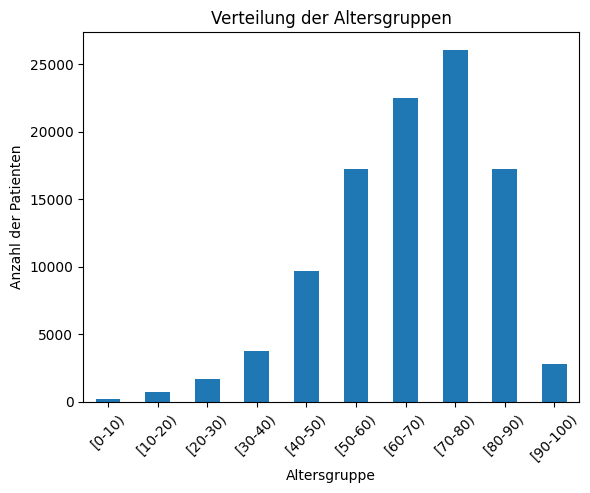

In [22]:
df["age"].value_counts().sort_index().plot(
    kind="bar",
    title="Verteilung der Altersgruppen"
)

plt.xlabel("Altersgruppe")
plt.ylabel("Anzahl der Patienten")
plt.xticks(rotation=45)
plt.show()

4. #### Wie lange bleiben die Patienten im Krankenhaus?
Die Variable heißt time_in_hospital.

Sie gibt die Anzahl der Tage im Krankenhaus an.

In [24]:
# Durchschnittliche Aufenthaltsdauer
print("Moyen:",df["time_in_hospital"].mean())

# Kürzester Aufenthalt
print("Kürzester Aufenthalt:", df["time_in_hospital"].min())

# Längster Aufenthalt
print("Längster Aufenthalt:", df["time_in_hospital"].max())

# Median
print("Median:", df["time_in_hospital"].median())

Moyen: 4.395986871843248
Kürzester Aufenthalt: 1
Längster Aufenthalt: 14
Median: 4.0


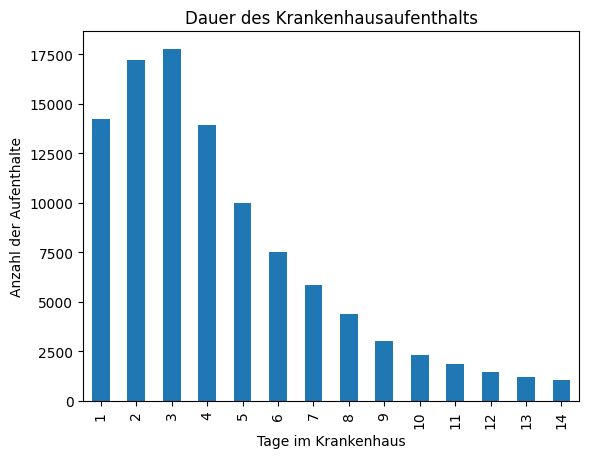

In [25]:
df["time_in_hospital"].value_counts().sort_index().plot(
    kind="bar",
    title="Dauer des Krankenhausaufenthalts"
)

plt.xlabel("Tage im Krankenhaus")
plt.ylabel("Anzahl der Aufenthalte")
plt.show()